# Phase 1: Resolution study

## Section 1 - Purpose and overview

This study looks at the input resolution of C-RADIO: 1024x1024, the native size of the headset frames, or 512x512.

Frames have entered the model at 1024 so far, but this was never a motivated choice. Perception takes about 400 ms per frame at 1024, almost all of it in C-RADIO (pipeline, Section 12). In a Vision Transformer the cost of global attention grows with the square of the number of tokens (C-RADIOv4 tech report, Sect. 3.2), and at 512 there are four times fewer tokens.

Both resolutions are legitimate for this model. It was trained by sampling the input resolution from a set that contains both 512 and 1024 (tech report, Sect. 2.2). Its configuration files give 512x512 as the preferred resolution (config.json, common.py), without documenting what this means.

The question is what is lost at 512. A patch then covers 32x32 pixels of the frame, so a small piece covers about four times fewer patches. On a generic benchmark the loss is small: a linear probe of C-RADIOv4-H on ADE20k goes from 57.02 at 1024 to 55.20 at 512 (tech report, Table 2). In Cityscapes, halving the resolution of the labels hardly changes the IoU but clearly lowers the instance-level score, because small objects are hit hardest (Cordts et al. 2016, Sect. 3.2). Our pieces are small.

Everything except the resolution stays fixed: the 8 reference frames, the labelling rule, the prototypes, the classifier, the background margins (0 and 0.03) and the validation frames. Both resolutions are evaluated on the same ground truth, the 64x64 patch grid at 1024. Each prediction at 512 is copied to the 2x2 block of 1024 patches it covers. Cityscapes evaluates labels at a lower resolution in the same way, after resampling them to full resolution (Sect. 3.2).

The study was first planned as a decision with a noninferiority rule: 512 would replace 1024 if it was not worse by more than a margin declared in advance (Piaggio et al. 2012). Section 4 computed this margin and two oracles, the best scores that a perfect recognizer could reach at 512, before any feature was extracted at 512. Even the more favourable oracle (0.705, arms merged) stays just above the threshold the rule required (about 0.699, against 0.709 for the method at 1024). With patch-level IoU on the 1024 grid, 512 could pass only with almost perfect recognition: the rule would measure the coarseness of the grid, not recognition. It was dropped.

The choice is made on what Section 4 shows without running 512. At 512 the prototypes of the small pieces rest on very few patches, one for arm_2 and two for mouth, and the coarser grid alone costs more IoU than all the errors of the method at 1024 on hat, nose and moustache. The small pieces are those Phase 2 depends on: the mouth and its empty slot, nose and moustache, the two arms. The gain in time is not needed now: continuous perception runs offline and the final system is planned as client-server, with C-RADIO on a server rather than on this laptop. 1024 is kept.

Section 5 runs 512 once, as a description: per-class IoU and latency, to know what 512 would cost and what it would gain. It is written before running and does not change the choice, so it is not a selection made on validation (Cawley and Talbot 2010, Sect. 4.4 and 5). The test sequence (assembly_1) is not read.

Section 3 checks that the shared code reproduces the previous results at 1024. Section 4 prepares the labels at 512 and computes the margins and the oracles. Section 5 describes 512, and Section 6 concludes.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

C-RADIOv4 tech report (Ranzinger et al. 2026), Sect. 2.2: the input resolution is sampled during training from {128, 192, 224, 256, 384, 432} and {512, 768, 1024, 1152}. Table 2: ADE20k linear probe of C-RADIOv4-H, 55.20 at 512 and 57.02 at 1024. Sect. 3.2: global attention has complexity O(T²) in the number of tokens T.

C-RADIOv4-SO400M model files (Hugging Face, commit c0457f5): config.json and common.py, preferred_resolution 512x512.

Cordts et al. 2016, Cityscapes, Sect. 3.2: labels subsampled by majority vote and resampled to full resolution give an upper bound for a fixed output resolution; subsampling by 2 hardly changes the IoU but lowers the instance-level score, which weighs small objects more. Sect. 3.4: downscaling consistently lowers performance, because of the large variation in object scale.

Cawley and Talbot 2010, Sect. 4.4: selecting by optimizing a criterion on a finite sample over-fits, more with small samples and many choices; Sect. 5: a performance estimate on the data used for selection is optimistically biased.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, frames and hyperparameters in one place. The values are the same as in the pipeline (Section 2.5) and in the support-set study (Section 2.4): this study changes only the input resolution.

In [1]:
# 2.1 Dependencies: install once per environment with pip install -r requirements.txt (README, Setup)

In [2]:
# 2.2 Imports
%load_ext autoreload
%autoreload 2

import sys
import json
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
import transformers
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy import ndimage

In [ ]:
# 2.3 Paths and shared module
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_resolution_study"
PIPELINE_DIR = PROJECT_ROOT / "outputs" / "phase_1_perception"
PIPELINE_PROTOTYPES_PATH = PIPELINE_DIR / "prototypes.npz"                    # saved by the pipeline (v1.3): 8 reference frames, 1024
PIPELINE_SIMILARITIES_PATH = PIPELINE_DIR / "validation_similarities.npz"     # saved by the pipeline (v1.3): 8 validation frames, 1024

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "SRC_DIR": SRC_DIR,
                   "PIPELINE_PROTOTYPES_PATH": PIPELINE_PROTOTYPES_PATH,
                   "PIPELINE_SIMILARITIES_PATH": PIPELINE_SIMILARITIES_PATH}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception), the same used by the pipeline and the support-set study
from perception.classes import (CLASS_NAMES, BACKGROUND_ID, HAND_LABEL, PIECE_LABELS, IGNORE_ID,
                                CLASS_COLORS, PATCH_LABEL_NAMES)
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import build_prototypes, stack_prototypes, load_prototypes, classify_patches
from perception.metrics import (confusion_matrix, iou_from_confusions, mean_iou, ignore_boundary_ring,
                                MERGED_NAMES, MERGED_PIECES, upsample_labels, merge_arms,
                                frame_iou, frame_miou, bootstrap_miou, bootstrap_class_iou,
                                percentile_interval, merged_ids)
from perception.visualization import label_grid_to_rgb

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src
[OK] PIPELINE_PROTOTYPES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\prototypes.npz
[OK] PIPELINE_SIMILARITIES_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\validation_similarities.npz


In [4]:
# 2.4 Hyperparameters
# Same values as the pipeline (Section 2.5) and the support-set study (Section 2.4).
# The only new parameters are the two resolutions and the latency runs.

# --- Feature extraction ---
DEVICE = "cuda"
DTYPE = torch.bfloat16
NATIVE_RESOLUTION = 1024        # headset frames; also the resolution of the ground truth (64x64 patch grid)
LOW_RESOLUTION = 512            # the alternative: a training resolution (tech report, Sect. 2.2), preferred in config.json
RESOLUTIONS = [NATIVE_RESOLUTION, LOW_RESOLUTION]
UPSAMPLE_FACTOR = NATIVE_RESOLUTION // LOW_RESOLUTION   # one 512 patch = a 2x2 block of 1024 patches
assert NATIVE_RESOLUTION % LOW_RESOLUTION == 0, "The two patch grids must align exactly"

# --- Patch labelling ---
MIN_LABEL_COVERAGE = 0.5        # same rule as the pipeline (Section 5), at both resolutions

# --- Classification ---
CONFIDENCE_MARGIN = 0.03        # background margin, provisional (pipeline, Section 9): not tuned here
EVAL_MARGINS = [0.0, CONFIDENCE_MARGIN]   # 0.0 = pure nearest prototype, independent of the provisional value

# --- Evaluation ---
N_BOOTSTRAP = 1000              # resamples of the validation frames (support-set study, Section 5.4)
BOUNDARY_RING = 1               # secondary metric: background patches within 1 patch of an object are ignored

# --- Latency (Section 5), same protocol as the pipeline, Section 12 ---
N_WARMUP, N_RUNS = 5, 50

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [5]:
# 2.5 Frames and split
# Validation: errors are inspected and the resolution is described here.
# Test: held out until the end of all studies. This notebook never reads a test frame.
VALIDATION_SEQUENCES = {"assembly_2", "1_disassembled_controlled_caos"}
TEST_SEQUENCES = {"assembly_1"}
assert not VALIDATION_SEQUENCES & TEST_SEQUENCES


def frame_path(frame, suffix=".jpg"):
    """Path of a frame or of its annotation. Refuses test frames, so the test set cannot be read by mistake."""
    assert sequence_of(frame) not in TEST_SEQUENCES, f"{frame} belongs to the held-out test set"
    return FRAMES_DIR / f"{frame}{suffix}"


# Selected support set (support-set study, Section 6.5), in the order of the pipeline (Section 4.1):
# the regression check (Section 3) compares with the prototypes the pipeline saved.
REFERENCE_FRAMES = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "5_assembled_f0019",            "role": "assembled, 3/4 view",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL}},
]

# v1-baseline support set (7 frames): used only in the regression check, to reproduce the paired
# comparison of the support-set study with the new shared functions.
BASELINE_REFERENCE_FRAMES = [ref for ref in REFERENCE_FRAMES if ref["frame"] != "5_assembled_f0019"]

# Validation frames in the order of the support-set study (Section 2.5): bootstrap resamples pick frames
# by position, so the same order is needed to reproduce its intervals.
VALIDATION_FRAMES = [
    {"frame": "assembly_2_f0003", "stage": "all pieces loose"},
    {"frame": "assembly_2_f0017", "stage": "body on base"},
    {"frame": "assembly_2_f0030", "stage": "hands: piece held in hand"},
    {"frame": "assembly_2_f0046", "stage": "face (eyes, nose, moustache, mouth)"},
    {"frame": "assembly_2_f0057", "stage": "ears mounted"},
    {"frame": "assembly_2_f0068", "stage": "arms mounted"},
    {"frame": "1_disassembled_controlled_caos_f0001", "stage": "disassembled, front view", "exclude": {"base"}},
    {"frame": "1_disassembled_controlled_caos_f0016", "stage": "disassembled, side view",  "exclude": {"base"}},
]

# No leakage: reference frames never come from validation or test sequences
for ref in REFERENCE_FRAMES:
    assert sequence_of(ref["frame"]) not in VALIDATION_SEQUENCES | TEST_SEQUENCES, f"Leakage: {ref['frame']}"
    ref["image_path"], ref["json_path"] = frame_path(ref["frame"]), frame_path(ref["frame"], ".json")
for val in VALIDATION_FRAMES:
    assert sequence_of(val["frame"]) in VALIDATION_SEQUENCES, f"{val['frame']} is not a validation frame"
    assert frame_path(val["frame"]).exists(), f"Missing frame: {val['frame']}"

# Ground truth: every official class is evaluated; legacy labels (shoe, pants) become ignored patches
GT_LABELS = PIECE_LABELS | {HAND_LABEL}

print(f"{len(REFERENCE_FRAMES)} reference frames ({len(BASELINE_REFERENCE_FRAMES)} in v1-baseline), "
      f"{len(VALIDATION_FRAMES)} validation frames")

8 reference frames (7 in v1-baseline), 8 validation frames


In [6]:
# 2.6 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


------------------------------------------------------------------------------------------------------------------------------------------

References Section 2: none. The values are taken from the pipeline (Section 2.5) and the support-set study (Section 2.4).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Regression check at 1024

The shared code changed for this study: the feature extractor accepts an input resolution, and the bootstrap and arm-merging functions moved from the support-set study to src/perception/metrics.py. Before comparing resolutions, this section checks that the changed code reproduces the previous results at 1024. Otherwise a difference between 1024 and 512 could come from the code and not from the resolution.

Three things are checked. The prototypes and the validation similarities must be bitwise identical to the files saved by the pipeline (v1.3). An exact comparison is possible because feature extraction is deterministic on this machine (support-set study, Section 3.2), although this is not guaranteed in general across releases or platforms (PyTorch documentation, Reproducibility). The new metric functions must give the numbers of the support-set study, for the baseline and the selected support set. These were printed with three decimals, so the comparison is at three decimals.

This section also prepares what the next sections use at 1024: patch labels and features of the reference frames, ground truth and features of the validation frames, and the bootstrap resamples, drawn exactly as in the support-set study (Section 5.4).

In [7]:
# 3.1 Loading the model (shared FeatureExtractor, same settings as the pipeline)
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
PATCH_SIZE = extractor.patch_size
print(f"Model loaded, patch size {PATCH_SIZE}x{PATCH_SIZE}")


def label_cell(resolution):
    """Side, in native pixels, of the frame area seen by one patch at this resolution (16 at 1024, 32 at 512)."""
    return PATCH_SIZE * NATIVE_RESOLUTION // resolution

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded, patch size 16x16


In [8]:
# 3.2 Reference frames at 1024: patch labels, features and prototypes, compared with the pipeline file.
# The polygons are rasterized once at native resolution; patch labels at any resolution come from this map.
for ref in REFERENCE_FRAMES:
    check_annotation(ref["image_path"], ref["json_path"])
    image = Image.open(ref["image_path"]).convert("RGB")
    assert image.size == (NATIVE_RESOLUTION, NATIVE_RESOLUTION), f"Unexpected size in {ref['frame']}"
    ref["pixel_map"] = rasterize_annotation(ref["json_path"], ref["use_labels"], image.size)
    ref["patch_labels"] = {NATIVE_RESOLUTION: patch_label_grid(ref["pixel_map"], label_cell(NATIVE_RESOLUTION),
                                                               MIN_LABEL_COVERAGE)[0]}
    ref["features"] = {NATIVE_RESOLUTION: extractor.extract(image, resolution=NATIVE_RESOLUTION)[0]}


def at_resolution(frames, resolution):
    """Reference frames in the format of build_prototypes, at one resolution."""
    return [{"features": f["features"][resolution], "patch_labels": f["patch_labels"][resolution]} for f in frames]


prototypes_1024, counts_1024 = build_prototypes(at_resolution(REFERENCE_FRAMES, NATIVE_RESOLUTION))
prototype_matrix_1024 = stack_prototypes(prototypes_1024)

pipeline = load_prototypes(PIPELINE_PROTOTYPES_PATH)
assert pipeline["class_names"] == CLASS_NAMES, "Class order differs from the pipeline file"
print("Patch counts identical      :", [counts_1024[name] for name in CLASS_NAMES] == list(pipeline["patch_counts"]))
print("Prototypes bitwise identical:", np.array_equal(prototype_matrix_1024, pipeline["prototypes"]))

Patch counts identical      : True
Prototypes bitwise identical: True


Observation 3.2: Rebuilt from the 8 reference frames with the modified feature extractor, the prototypes have the same patch counts as the pipeline file and are bitwise identical to it.

In [9]:
# 3.3 Validation frames at 1024: ground truth (same rules as the support-set study, Section 4.2) and features.
# Similarities with the selected prototypes are compared with the file saved by the pipeline (stored by frame name).
with np.load(PIPELINE_SIMILARITIES_PATH) as data:
    pipeline_similarities = {key: data[key] for key in data.files if key.endswith("__similarities")}

identical = []
for val in VALIDATION_FRAMES:
    image_path, json_path = frame_path(val["frame"]), frame_path(val["frame"], ".json")
    check_annotation(image_path, json_path)
    image = Image.open(image_path).convert("RGB")
    val["pixel_map"] = rasterize_annotation(json_path, GT_LABELS, image.size)
    val["gt_labels"], _ = patch_label_grid(val["pixel_map"], label_cell(NATIVE_RESOLUTION), MIN_LABEL_COVERAGE)
    val["gt_tolerant"] = ignore_boundary_ring(val["gt_labels"], BOUNDARY_RING)
    val["excluded_ids"] = {CLASS_NAMES.index(name) for name in val.get("exclude", set())}
    val["features"] = {NATIVE_RESOLUTION: extractor.extract(image, resolution=NATIVE_RESOLUTION)[0]}
    _, similarities = classify_patches(val["features"][NATIVE_RESOLUTION], prototype_matrix_1024, CONFIDENCE_MARGIN)
    identical.append(np.array_equal(similarities, pipeline_similarities[f"{val['frame']}__similarities"]))

EXCLUDED = [val["excluded_ids"] for val in VALIDATION_FRAMES]
print(f"Similarities bitwise identical on {sum(identical)} of {len(identical)} validation frames")

Similarities bitwise identical on 8 of 8 validation frames


Observation 3.3: On all 8 validation frames, the similarities with these prototypes are bitwise identical to those saved by the pipeline. The new resolution option leaves the path at 1024 unchanged.

In [10]:
# 3.4 Evaluation functions and bootstrap resamples (drawn as in the support-set study, Section 5.4)
def predict(features, prototype_matrix, margin, resolution):
    """Patch labels on the 64x64 ground-truth grid: at a lower resolution each label is copied to its block."""
    labels, _ = classify_patches(features, prototype_matrix, margin)
    return upsample_labels(labels, NATIVE_RESOLUTION // resolution)


def evaluate(prototype_matrix, margin, resolution, gt_key="gt_labels"):
    """Per-frame confusion matrices on the validation frames, always against the 1024 ground truth.
    gt_key: "gt_labels" (main metric) or "gt_tolerant" (boundary ring ignored)."""
    return [confusion_matrix(val[gt_key], predict(val["features"][resolution], prototype_matrix, margin, resolution))
            for val in VALIDATION_FRAMES]


rng = np.random.default_rng(RANDOM_SEED)
BOOTSTRAP_INDICES = rng.integers(0, len(VALIDATION_FRAMES), size=(N_BOOTSTRAP, len(VALIDATION_FRAMES)))
print(f"{N_BOOTSTRAP} bootstrap resamples of {len(VALIDATION_FRAMES)} validation frames")

1000 bootstrap resamples of 8 validation frames


In [11]:
# 3.5 New shared metrics vs the numbers printed in the support-set study (three decimals)
baseline_matrix = stack_prototypes(build_prototypes(at_resolution(BASELINE_REFERENCE_FRAMES, NATIVE_RESOLUTION))[0])
conf = {(name, gt_key, margin): evaluate(matrix, margin, NATIVE_RESOLUTION, gt_key)
        for name, matrix in [("baseline", baseline_matrix), ("selected", prototype_matrix_1024)]
        for gt_key in ["gt_labels", "gt_tolerant"] for margin in EVAL_MARGINS}


def check(quantity, values, expected):
    obtained = [round(float(v), 3) for v in values]
    return {"quantity": quantity, "obtained": obtained, "support-set study": expected, "match": obtained == expected}


rows = []
# Baseline, 10 pieces: mIoU and 95% interval (study, Section 5.4)
for gt_key, margin, expected in [("gt_labels", 0.0, [0.594, 0.551, 0.649]),
                                 ("gt_labels", CONFIDENCE_MARGIN, [0.648, 0.602, 0.700]),
                                 ("gt_tolerant", 0.0, [0.747, 0.705, 0.795]),
                                 ("gt_tolerant", CONFIDENCE_MARGIN, [0.757, 0.716, 0.800])]:
    c = conf[("baseline", gt_key, margin)]
    rows.append(check(f"baseline, 10 pieces, {gt_key}, margin {margin}",
                      [frame_miou(c, EXCLUDED), *percentile_interval(bootstrap_miou(c, EXCLUDED, BOOTSTRAP_INDICES))],
                      expected))

# Selected vs baseline, background margin 0.03 (study, Sections 6.4, 6.7 and 8)
for gt_key, expected_merged in [("gt_labels", [0.667, 0.709, 0.042, 0.025, 0.059]),
                                ("gt_tolerant", [0.783, 0.805, 0.023, 0.007, 0.042])]:
    b, s = conf[("baseline", gt_key, CONFIDENCE_MARGIN)], conf[("selected", gt_key, CONFIDENCE_MARGIN)]
    b_miou, s_miou = frame_miou(b, EXCLUDED, merge=True), frame_miou(s, EXCLUDED, merge=True)
    delta = (bootstrap_miou(s, EXCLUDED, BOOTSTRAP_INDICES, merge=True)
             - bootstrap_miou(b, EXCLUDED, BOOTSTRAP_INDICES, merge=True))
    rows.append(check(f"arms merged, {gt_key}: baseline, selected, delta, delta interval",
                      [b_miou, s_miou, s_miou - b_miou, *percentile_interval(delta)], expected_merged))

s = conf[("selected", "gt_labels", CONFIDENCE_MARGIN)]
b = conf[("baseline", "gt_labels", CONFIDENCE_MARGIN)]
delta_10 = bootstrap_miou(s, EXCLUDED, BOOTSTRAP_INDICES) - bootstrap_miou(b, EXCLUDED, BOOTSTRAP_INDICES)
rows.append(check("selected, 10 pieces, gt_labels: mIoU", [frame_miou(s, EXCLUDED)], [0.658]))
rows.append(check("selected, 10 pieces, gt_tolerant: mIoU",
                  [frame_miou(conf[("selected", "gt_tolerant", CONFIDENCE_MARGIN)], EXCLUDED)], [0.737]))
rows.append(check("selected - baseline, 10 pieces, gt_labels: delta interval",
                  list(percentile_interval(delta_10)), [-0.025, 0.047]))

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(rows))

,quantity,obtained,support-set study,match
0,"baseline, 10 pieces, gt_labels, margin 0.0","[0.594, 0.551, 0.649]","[0.594, 0.551, 0.649]",True
1,"baseline, 10 pieces, gt_labels, margin 0.03","[0.648, 0.602, 0.7]","[0.648, 0.602, 0.7]",True
2,"baseline, 10 pieces, gt_tolerant, margin 0.0","[0.747, 0.705, 0.795]","[0.747, 0.705, 0.795]",True
3,"baseline, 10 pieces, gt_tolerant, margin 0.03","[0.757, 0.716, 0.8]","[0.757, 0.716, 0.8]",True
4,"arms merged, gt_labels: baseline, selected, delta, delta interval","[0.667, 0.709, 0.042, 0.025, 0.059]","[0.667, 0.709, 0.042, 0.025, 0.059]",True
5,"arms merged, gt_tolerant: baseline, selected, delta, delta interval","[0.783, 0.805, 0.023, 0.007, 0.042]","[0.783, 0.805, 0.023, 0.007, 0.042]",True
6,"selected, 10 pieces, gt_labels: mIoU",[0.658],[0.658],True
7,"selected, 10 pieces, gt_tolerant: mIoU",[0.737],[0.737],True
8,"selected - baseline, 10 pieces, gt_labels: delta interval","[-0.025, 0.047]","[-0.025, 0.047]",True


Observation 3.5: The new shared functions give every number printed in the support-set study, to three decimals. For the baseline, the mIoU over 10 pieces is 0.648 with the interval [0.602, 0.700] at background margin 0.03. With the arms merged, the mIoU is 0.667 for the baseline and 0.709 for the selected support set, a paired difference of +0.042 with the interval [0.025, 0.059]. Over 10 pieces, the interval of the difference is [−0.025, 0.047].

The bootstrap resamples are therefore the same as in the study. A difference between 1024 and 512 in the next sections cannot come from the changes to the shared code.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3: PyTorch documentation, Reproducibility (docs.pytorch.org/docs/stable/notes/randomness.html): completely reproducible results are not guaranteed across releases, commits or platforms, and GPU libraries may select different algorithms on subsequent runs, even on the same machine.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Labels at 512, noninferiority margins and oracles

This section prepares everything that does not need C-RADIO at 512. It was written and run before any feature was extracted at 512.

4.1 labels the reference patches at 512 with the same coverage rule as at 1024, applied to the 32x32 native pixels each patch sees, and counts how many patches each class keeps. A prototype is the mean of these patches (pipeline, Section 6), so a class with few patches gets a fragile prototype.

4.2 computes the noninferiority margins of the decision rule planned at first. A noninferiority margin is the largest loss accepted, declared before the comparison and justified by the use (Piaggio et al. 2012, Items 2b and 7a). Phase 2 checks pieces, so the margin of a piece is the IoU that the method at 1024 would lose by missing that piece in one typical frame: its correctly predicted patches divided by the union of its class over the validation frames, as a median over its instances. The margin on the mIoU is the median of the piece margins divided by the number of classes, 9 with the arms merged. Every class is one physical piece except ear, which has two identical pieces, so ear instances are separated in the ground truth, with the limitation described in Observation 4.2.

4.3 computes the oracle of Cityscapes: the ground truth reduced to the 512 grid by majority vote of the pixels and copied back to the 64x64 grid (Cordts et al. 2016, Sect. 3.2). It estimates what the coarser grid costs even when every piece is recognized.

4.4 was added after seeing 4.3. In our ground truth the mixed border patches are ignored, so the majority of the pixels is too pessimistic: a cell that is 40% nose takes background, while the evaluated patches inside it are nose. The second oracle lets only the evaluated patches vote, so it is the best that a prediction at 512 can score with our metric. It is our own construction, not taken from a paper.

In [12]:
# 4.1 Reference patch labels at 512: the same coverage rule, applied to the 32x32 native pixels each patch sees
for ref in REFERENCE_FRAMES:
    labels_low, _ = patch_label_grid(ref["pixel_map"], label_cell(LOW_RESOLUTION), MIN_LABEL_COVERAGE)
    assert labels_low.shape == (LOW_RESOLUTION // PATCH_SIZE,) * 2, f"Unexpected grid in {ref['frame']}"
    ref["patch_labels"][LOW_RESOLUTION] = labels_low

# Patches per class over all reference frames, and in how many frames each class has at least one patch
rows = {}
for class_id, name in enumerate(CLASS_NAMES):
    counts = {res: [int((ref["patch_labels"][res] == class_id).sum()) for ref in REFERENCE_FRAMES]
              for res in RESOLUTIONS}
    rows[name] = {
        f"patches {NATIVE_RESOLUTION}": sum(counts[NATIVE_RESOLUTION]),
        f"patches {LOW_RESOLUTION}": sum(counts[LOW_RESOLUTION]),
        "ratio": round(sum(counts[NATIVE_RESOLUTION]) / max(sum(counts[LOW_RESOLUTION]), 1), 1),
        f"frames {NATIVE_RESOLUTION}": sum(c > 0 for c in counts[NATIVE_RESOLUTION]),
        f"frames {LOW_RESOLUTION}": sum(c > 0 for c in counts[LOW_RESOLUTION]),
    }
display(pd.DataFrame(rows).T)

# Detail: patches per class and reference frame at 512
display(pd.DataFrame({ref["frame"]: [int((ref["patch_labels"][LOW_RESOLUTION] == i).sum())
                                     for i in range(len(CLASS_NAMES))]
                      for ref in REFERENCE_FRAMES}, index=CLASS_NAMES))

,patches 1024,patches 512,ratio,frames 1024,frames 512
background,30698.0,7523.0,4.1,8.0,8.0
body,251.0,61.0,4.1,5.0,5.0
base,201.0,51.0,3.9,5.0,5.0
hat,52.0,11.0,4.7,5.0,5.0
eyes,32.0,5.0,6.4,5.0,3.0
ear,52.0,12.0,4.3,5.0,5.0
nose,29.0,6.0,4.8,5.0,3.0
moustache,35.0,5.0,7.0,5.0,4.0
mouth,24.0,2.0,12.0,5.0,2.0
arm_1,33.0,7.0,4.7,5.0,4.0


,5_assembled_f0002,caos_f0149,5_assembled_f0019,3_disassembled_ordered_f0001,2_disassembled_caos_f0016,Take_3_1_Base_f0099,Take_3_1_Base_f0131,caos_f0211
background,981,940,979,901,932,1002,998,790
body,6,10,5,25,15,0,0,0
base,6,16,5,0,0,9,15,0
hat,3,1,3,2,2,0,0,0
eyes,1,2,2,0,0,0,0,0
ear,4,2,3,1,2,0,0,0
nose,1,3,2,0,0,0,0,0
moustache,1,2,1,1,0,0,0,0
mouth,1,1,0,0,0,0,0,0
arm_1,1,4,1,1,0,0,0,0


Observation 4.1: The large classes keep about one patch in four at 512, as the area alone predicts: body goes from 251 to 61 patches, base from 201 to 51, ear from 52 to 12. The small and thin pieces lose much more: eyes from 32 to 5, moustache from 35 to 5, mouth from 24 to 2, arm_2 from 15 to 1.

They also disappear from some reference frames. At 512 mouth is present in 2 frames instead of 5, eyes and nose in 3 instead of 5, arm_2 in 1 instead of 4. The prototype of arm_2 would rest on a single patch.

In [13]:
# 4.2 Noninferiority margins (option B): the IoU that 1024 would lose by missing one typical piece in one frame.
# Computed from the ground truth and the 1024 predictions only: no feature at 512 is used.
EAR_ID = CLASS_NAMES.index("ear")
ARM_IDS = [CLASS_NAMES.index("arm_1"), CLASS_NAMES.index("arm_2")]


def piece_instances(gt_labels, class_id):
    """One boolean mask per physical piece of this class in one frame.
    Every class is one physical piece (a piece split by fingers stays one instance), except ear:
    two identical pieces, separated as groups of touching ear patches (8-connectivity)."""
    mask = gt_labels == class_id
    if not mask.any():
        return []
    if class_id != EAR_ID:
        return [mask]
    components, n = ndimage.label(mask, structure=np.ones((3, 3)))
    return [components == k for k in range(1, n + 1)]


# Check: ear instances found in each validation frame (to compare with the ears actually visible)
print("Ear instances per frame:", {val["frame"]: len(piece_instances(val["gt_labels"], EAR_ID))
                                   for val in VALIDATION_FRAMES})


def merged_unions(confusions):
    """TP + FP + FN per class with the arms merged, summed over the frames (exclusions applied)."""
    unions = np.zeros(len(MERGED_NAMES))
    for confusion, excluded in zip(confusions, EXCLUDED):
        merged = merge_arms(confusion)
        keep = ~np.isin(np.arange(len(MERGED_NAMES)), list(merged_ids(excluded)))
        unions += keep * (merged.sum(axis=0) + merged.sum(axis=1) - np.diag(merged))
    return unions


NONINFERIORITY = {}
margin_tables = {}
for margin in EVAL_MARGINS:
    confusions = conf[("selected", "gt_labels", margin)]          # computed in 3.5, at 1024
    unions = merged_unions(confusions)
    losses = {name: [] for name in MERGED_NAMES if name in MERGED_PIECES}
    sizes = {name: [] for name in losses}
    for val in VALIDATION_FRAMES:
        pred = predict(val["features"][NATIVE_RESOLUTION], prototype_matrix_1024, margin, NATIVE_RESOLUTION)
        for class_id, name in enumerate(CLASS_NAMES):
            if name not in PIECE_LABELS or class_id in val["excluded_ids"]:
                continue
            merged_name = "arm" if class_id in ARM_IDS else name
            correct = np.isin(pred, ARM_IDS) if class_id in ARM_IDS else pred == class_id
            for instance in piece_instances(val["gt_labels"], class_id):
                union = unions[MERGED_NAMES.index(merged_name)]
                losses[merged_name].append(int((instance & correct).sum()) / union)
                sizes[merged_name].append(int(instance.sum()))

    class_margins = {name: float(np.median(v)) for name, v in losses.items()}
    miou_margin = float(np.median(list(class_margins.values()))) / len(class_margins)
    NONINFERIORITY[margin] = {"miou": miou_margin, "per_class": class_margins}
    margin_tables[margin] = pd.DataFrame({"instances": {n: len(v) for n, v in losses.items()},
                                          "median patches": {n: float(np.median(v)) for n, v in sizes.items()},
                                          "class margin": class_margins})
    print(f"Background margin {margin}: noninferiority margin on the mIoU (arms merged) = {miou_margin:.4f}")
    display(margin_tables[margin].round(4))

# Written record of what was fixed before any feature at 512 was extracted
with open(OUTPUT_DIR / "noninferiority_margins.json", "w") as f:
    json.dump({str(m): v for m, v in NONINFERIORITY.items()}, f, indent=2)

Ear instances per frame: {'assembly_2_f0003': 1, 'assembly_2_f0017': 1, 'assembly_2_f0030': 1, 'assembly_2_f0046': 1, 'assembly_2_f0057': 2, 'assembly_2_f0068': 2, '1_disassembled_controlled_caos_f0001': 2, '1_disassembled_controlled_caos_f0016': 2}
Background margin 0.0: noninferiority margin on the mIoU (arms merged) = 0.0099


,instances,median patches,class margin
body,8,47.5,0.0887
base,6,24.0,0.0889
hat,8,18.0,0.1125
eyes,8,7.0,0.0886
ear,12,6.0,0.0500
nose,8,6.0,0.0887
moustache,8,6.0,0.0938
mouth,8,4.5,0.0556
arm,16,6.0,0.0341


Background margin 0.03: noninferiority margin on the mIoU (arms merged) = 0.0101


,instances,median patches,class margin
body,8,47.5,0.0969
base,6,24.0,0.1000
hat,8,18.0,0.1216
eyes,8,7.0,0.0909
ear,12,6.0,0.0606
nose,8,6.0,0.0902
moustache,8,6.0,0.0984
mouth,8,4.5,0.0556
arm,16,6.0,0.0395


Observation 4.2: The margin on the mIoU, arms merged, is 0.0099 at background margin 0 and 0.0101 at 0.03. The piece margins range from 0.0341 (arm) to 0.1125 (hat) at background margin 0, and from 0.0395 (arm) to 0.1216 (hat) at 0.03. A typical instance covers 4.5 patches for mouth, 6 for nose, moustache, ear and each arm, and 47.5 for body.

Limitation: ear instances are separated as groups of touching patches. In assembly_2_f0003, f0017, f0030 and f0046 two ears are visible, but only one group is found, because the loose ears lie a few pixels apart and their patches touch. The ear margin therefore counts the two ears of these frames as one instance. Since the margins are no longer used for a decision (Section 1), this definition was not corrected.

In [14]:
# 4.3 Oracle: the ground truth reduced to the grid of a resolution by majority vote of the pixels
# (Cordts et al. 2016, Sect. 3.2) and copied back to the 64x64 grid, evaluated as a prediction.
def oracle_labels(pixel_map, cell):
    """Majority class of the native pixels in each cell (background included). Ties: the lowest class index wins,
    so background first. Cells where ignored polygons win (legacy shoe, pants) become background."""
    _, fractions = patch_label_grid(pixel_map, cell, MIN_LABEL_COVERAGE)
    majority = fractions.argmax(axis=-1)
    majority[majority == IGNORE_ID] = BACKGROUND_ID
    return majority


oracle_conf = {(res, gt_key): [confusion_matrix(val[gt_key],
                                                upsample_labels(oracle_labels(val["pixel_map"], label_cell(res)),
                                                                NATIVE_RESOLUTION // res))
                               for val in VALIDATION_FRAMES]
               for res in RESOLUTIONS for gt_key in ["gt_labels", "gt_tolerant"]}

display(pd.DataFrame({f"oracle {res}, {gt_key}": {"mIoU (10 pieces)": frame_miou(c, EXCLUDED),
                                                  "mIoU (arms merged)": frame_miou(c, EXCLUDED, merge=True)}
                      for (res, gt_key), c in oracle_conf.items()}).round(3))

# Per class, arms merged, main metric: which pieces the coarser grid costs most
display(pd.DataFrame({f"oracle {res}": frame_iou(oracle_conf[(res, "gt_labels")], EXCLUDED, merge=True)
                      for res in RESOLUTIONS}, index=MERGED_NAMES).round(3))

,"oracle 1024, gt_labels","oracle 1024, gt_tolerant","oracle 512, gt_labels","oracle 512, gt_tolerant"
mIoU (10 pieces),1.0,1.0,0.604,0.604
mIoU (arms merged),1.0,1.0,0.610,0.610


,oracle 1024,oracle 512
background,1.0,0.991
body,1.0,0.792
base,1.0,0.787
hat,1.0,0.763
eyes,1.0,0.617
ear,1.0,0.541
nose,1.0,0.439
moustache,1.0,0.493
mouth,1.0,0.477
arm,1.0,0.580


Observation 4.3: At 1024 the oracle scores 1.000, as it must, since it is the ground truth itself. At 512 the mIoU is 0.604 over 10 pieces and 0.610 with the arms merged. The small pieces lose most: nose 0.439, mouth 0.477, moustache 0.493, ear 0.541. Body (0.792) and base (0.787) lose least.

Ignoring the boundary ring gives the same values. A likely reason is the labelling rule: mixed border patches are ignored, so the coarser grid adds almost no false positives on the background. Its errors are missed piece patches, in cells where the piece covers less than half.

In [15]:
# 4.4 Second oracle, on the evaluated patches: each 2x2 block takes the most frequent ground-truth label among its
# non-ignored 1024 patches. A piece wins a tie with background, since the mIoU counts only pieces.
def patch_oracle_labels(gt_labels, factor):
    h, w = gt_labels.shape
    blocks = (gt_labels.reshape(h // factor, factor, w // factor, factor)
              .transpose(0, 2, 1, 3).reshape(h // factor, w // factor, factor * factor))
    votes = np.stack([(blocks == i).sum(axis=-1) for i in range(len(CLASS_NAMES))], axis=-1).astype(float)
    votes[..., 1:] += 0.5 * (votes[..., 1:] > 0)    # tie-break: a class present in the block beats background
    return votes.argmax(axis=-1)                     # ignored patches never vote; all-ignored blocks -> background


patch_oracle_conf = {gt_key: [confusion_matrix(val[gt_key],
                                               upsample_labels(patch_oracle_labels(val["gt_labels"], UPSAMPLE_FACTOR),
                                                               UPSAMPLE_FACTOR))
                              for val in VALIDATION_FRAMES]
                     for gt_key in ["gt_labels", "gt_tolerant"]}

reference = conf[("selected", "gt_labels", CONFIDENCE_MARGIN)]      # the method at 1024 (Section 3.5)
display(pd.DataFrame({
    "method 1024": {"mIoU (10 pieces)": frame_miou(reference, EXCLUDED),
                    "mIoU (arms merged)": frame_miou(reference, EXCLUDED, merge=True)},
    "pixel oracle 512": {"mIoU (10 pieces)": frame_miou(oracle_conf[(LOW_RESOLUTION, "gt_labels")], EXCLUDED),
                         "mIoU (arms merged)": frame_miou(oracle_conf[(LOW_RESOLUTION, "gt_labels")], EXCLUDED, merge=True)},
    "patch oracle 512": {"mIoU (10 pieces)": frame_miou(patch_oracle_conf["gt_labels"], EXCLUDED),
                         "mIoU (arms merged)": frame_miou(patch_oracle_conf["gt_labels"], EXCLUDED, merge=True)},
}).round(3))

# Per class, arms merged, main metric, background margin 0.03 for the method
display(pd.DataFrame({
    "method 1024": frame_iou(reference, EXCLUDED, merge=True),
    "pixel oracle 512": frame_iou(oracle_conf[(LOW_RESOLUTION, "gt_labels")], EXCLUDED, merge=True),
    "patch oracle 512": frame_iou(patch_oracle_conf["gt_labels"], EXCLUDED, merge=True),
}, index=MERGED_NAMES).round(3))

,method 1024,pixel oracle 512,patch oracle 512
mIoU (10 pieces),0.658,0.604,0.716
mIoU (arms merged),0.709,0.610,0.705


,method 1024,pixel oracle 512,patch oracle 512
background,0.991,0.991,0.994
body,0.764,0.792,0.840
base,0.778,0.787,0.810
hat,0.919,0.763,0.838
eyes,0.636,0.617,0.705
ear,0.697,0.541,0.693
nose,0.705,0.439,0.548
moustache,0.803,0.493,0.556
mouth,0.426,0.477,0.533
arm,0.651,0.580,0.820


Observation 4.4: The second oracle scores 0.716 over 10 pieces and 0.705 with the arms merged, against 0.658 and 0.709 for the method at 1024. For three pieces it stays below the method at 1024: hat (0.838 against 0.919), nose (0.548 against 0.705) and moustache (0.556 against 0.803). Ear is about equal (0.693 against 0.697). For these pieces the coarser grid alone costs more than all the errors of the method at 1024.

Consequence for the planned rule. To be noninferior, 512 needed a mIoU above about 0.699 with the arms merged, the method at 1024 minus the margin of 4.2. A perfect recognizer at 512 scores 0.705. The rule could be passed only with almost perfect recognition, so it measured the coarseness of the grid rather than recognition. It was dropped before any feature was extracted at 512 (Section 1).

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4:

Pipeline, Section 6: a prototype is the normalized mean of the annotated patches of its class 4.1.

Piaggio et al. 2012, Items 2b and 7a: the noninferiority margin is declared with the rationale for its choice and preferably justified by the use; a margin too narrow tends to give inconclusive results 4.2.

Cordts et al. 2016, Cityscapes, Sect. 3.2: labels subsampled by majority vote and resampled to full resolution give an upper bound for a fixed output resolution 4.3.

The second oracle (4.4) is our own construction.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - Description of 512

This section runs C-RADIO at 512 once, to describe what 512 would cost and what it would gain. It was written before running, and its results do not change the choice of 1024 made in Section 1.

Everything is built exactly as at 1024. The reference frames give their features at 512, and the prototypes are built with the patch labels of 4.1. The validation frames are classified with the same rule and background margins, and the predictions are copied to the 64x64 ground-truth grid (Section 3.4). The background margin of 0.03 was set at 1024 and is not tuned at 512, so margin 0, pure nearest prototype, is also reported.

5.1 compares the prototypes: for each class, its nearest other class and their cosine similarity at both resolutions. Close prototypes mean that a small change in a patch can switch its class (pipeline, Section 8).

5.2 compares recognition on the validation frames, with the paired bootstrap interval of the difference between 512 and 1024 (Koehn 2004, Sect. 6), next to the two oracles of Section 4.

5.3 shows the predictions at both resolutions on three frames chosen before running, one for each known limit of the method: the empty mouth slot (assembly_2_f0017), the small face pieces mounted (assembly_2_f0046) and the loose mouth seen from the side (1_disassembled_controlled_caos_f0016).

5.4 measures latency with the protocol of the pipeline (Section 12). The two resolutions are timed alternately in the same execution, so that slow changes in the state of the laptop affect both alike.

In [16]:
# 5.1 Features and prototypes at 512 (same reference frames, patch labels from 4.1)
for frame in REFERENCE_FRAMES + VALIDATION_FRAMES:
    image = Image.open(frame_path(frame["frame"])).convert("RGB")
    features, size = extractor.extract(image, resolution=LOW_RESOLUTION)
    assert size == (LOW_RESOLUTION, LOW_RESOLUTION), f"Unexpected input size for {frame['frame']}"
    frame["features"][LOW_RESOLUTION] = features

prototypes_512, counts_512 = build_prototypes(at_resolution(REFERENCE_FRAMES, LOW_RESOLUTION))
PROTOTYPE_MATRIX = {NATIVE_RESOLUTION: prototype_matrix_1024, LOW_RESOLUTION: stack_prototypes(prototypes_512)}


def nearest_classes(matrix):
    """For each class: its nearest other class and their cosine similarity (unit prototypes: dot product)."""
    similarity = matrix @ matrix.T
    np.fill_diagonal(similarity, -np.inf)
    nearest = similarity.argmax(axis=1)
    return {CLASS_NAMES[i]: (CLASS_NAMES[j], float(similarity[i, j])) for i, j in enumerate(nearest)}


nearest = {res: nearest_classes(PROTOTYPE_MATRIX[res]) for res in RESOLUTIONS}
display(pd.DataFrame({
    f"nearest {NATIVE_RESOLUTION}": {n: nearest[NATIVE_RESOLUTION][n][0] for n in CLASS_NAMES},
    f"cosine {NATIVE_RESOLUTION}": {n: nearest[NATIVE_RESOLUTION][n][1] for n in CLASS_NAMES},
    f"nearest {LOW_RESOLUTION}": {n: nearest[LOW_RESOLUTION][n][0] for n in CLASS_NAMES},
    f"cosine {LOW_RESOLUTION}": {n: nearest[LOW_RESOLUTION][n][1] for n in CLASS_NAMES},
}).round(3))

,nearest 1024,cosine 1024,nearest 512,cosine 512
background,hand,0.744,hand,0.735
body,base,0.836,base,0.853
base,body,0.836,body,0.853
hat,base,0.835,base,0.842
eyes,mouth,0.765,mouth,0.748
ear,nose,0.869,nose,0.822
nose,ear,0.869,moustache,0.850
moustache,nose,0.862,nose,0.850
mouth,nose,0.851,moustache,0.807
arm_1,arm_2,0.955,arm_2,0.829


Observation 5.1: The nearest class of each prototype is the same at both resolutions, except for nose (ear at 1024, moustache at 512) and mouth (nose at 1024, moustache at 512). Body and base become closer (0.836 to 0.853), and so do hat and base (0.835 to 0.842). Most face pairs move apart: ear and nose go from 0.869 to 0.822, mouth and its nearest class from 0.851 to 0.807.

The largest change is arm_1 and arm_2, from 0.955 to 0.829. This does not mean that the arms are better separated at 512. The arm_2 prototype at 512 is a single patch (Observation 4.1), so it is the vector of one patch rather than a mean. A likely reason for the lower similarity is this noisier prototype, not a better distinction between the two arms.

In [17]:
# 5.2 Recognition at 512 vs 1024, on the same 1024 ground truth (arms merged unless stated)
conf_512 = {(gt_key, margin): evaluate(PROTOTYPE_MATRIX[LOW_RESOLUTION], margin, LOW_RESOLUTION, gt_key)
            for gt_key in ["gt_labels", "gt_tolerant"] for margin in EVAL_MARGINS}

rows = []
for gt_key in ["gt_labels", "gt_tolerant"]:
    for margin in EVAL_MARGINS:
        c_1024, c_512 = conf[("selected", gt_key, margin)], conf_512[(gt_key, margin)]
        for merge in [False, True]:
            delta = (bootstrap_miou(c_512, EXCLUDED, BOOTSTRAP_INDICES, merge)
                     - bootstrap_miou(c_1024, EXCLUDED, BOOTSTRAP_INDICES, merge))
            low, high = percentile_interval(delta)
            rows.append({"metric": gt_key, "background margin": margin,
                         "classes": "arms merged" if merge else "10 pieces",
                         "mIoU 1024": frame_miou(c_1024, EXCLUDED, merge=merge),
                         "mIoU 512": frame_miou(c_512, EXCLUDED, merge=merge),
                         "delta (512 - 1024)": frame_miou(c_512, EXCLUDED, merge=merge) - frame_miou(c_1024, EXCLUDED, merge=merge),
                         "delta low": low, "delta high": high})
display(pd.DataFrame(rows).round(3))

# Per class, arms merged, main metric, next to the oracle of 4.4
display(pd.DataFrame({
    **{f"1024, margin {m}": frame_iou(conf[("selected", "gt_labels", m)], EXCLUDED, merge=True) for m in EVAL_MARGINS},
    **{f"512, margin {m}": frame_iou(conf_512[("gt_labels", m)], EXCLUDED, merge=True) for m in EVAL_MARGINS},
    "patch oracle 512": frame_iou(patch_oracle_conf["gt_labels"], EXCLUDED, merge=True),
}, index=MERGED_NAMES).round(3))

,metric,background margin,classes,mIoU 1024,mIoU 512,delta (512 - 1024),delta low,delta high
0,gt_labels,0.00,10 pieces,0.612,0.343,-0.269,-0.292,-0.246
1,gt_labels,0.00,arms merged,0.654,0.389,-0.265,-0.289,-0.241
2,gt_labels,0.03,10 pieces,0.658,0.379,-0.279,-0.311,-0.252
3,gt_labels,0.03,arms merged,0.709,0.432,-0.277,-0.302,-0.251
4,gt_tolerant,0.00,10 pieces,0.726,0.472,-0.254,-0.282,-0.232
5,gt_tolerant,0.00,arms merged,0.793,0.541,-0.251,-0.286,-0.221
6,gt_tolerant,0.03,10 pieces,0.737,0.503,-0.234,-0.266,-0.210
7,gt_tolerant,0.03,arms merged,0.805,0.580,-0.225,-0.262,-0.193


,"1024, margin 0.0","1024, margin 0.03","512, margin 0.0","512, margin 0.03",patch oracle 512
background,0.985,0.991,0.967,0.975,0.994
body,0.700,0.764,0.555,0.606,0.840
base,0.692,0.778,0.450,0.487,0.810
hat,0.850,0.919,0.571,0.607,0.838
eyes,0.620,0.636,0.393,0.541,0.705
ear,0.575,0.697,0.381,0.429,0.693
nose,0.694,0.705,0.410,0.410,0.548
moustache,0.766,0.803,0.289,0.289,0.556
mouth,0.426,0.426,0.120,0.120,0.533
arm,0.562,0.651,0.334,0.397,0.820


Observation 5.2: At 512 the mIoU is much lower than at 1024 in every setting. With the arms merged, at background margin 0.03 on the main metric, it goes from 0.709 to 0.432, a difference of −0.277 with the paired interval [−0.302, −0.251]. Over 10 pieces it goes from 0.658 to 0.379. With the boundary ring ignored, from 0.805 to 0.580. The difference lies between −0.225 and −0.279 in all eight settings, and every interval lies entirely below zero.

The loss is mostly recognition, not grid. The patch oracle of 4.4 reaches 0.705 with the arms merged, so 512 stays 0.273 below what a perfect recognizer on its grid would score. Every piece is below both 1024 and the oracle at background margin 0.03. Mouth goes to 0.120 (1024: 0.426, oracle: 0.533) and moustache to 0.289 (1024: 0.803, oracle: 0.556). The large pieces also drop well below the oracle: base 0.487 (oracle 0.810), body 0.606 (oracle 0.840), hat 0.607 (oracle 0.838).

For mouth, moustache and arm_2, the few reference patches at 512 (Observation 4.1) are a possible reason. They do not explain base, which keeps 51 reference patches at 512. Section 5.3 suggests another reason for base, its false positives on loose pieces.

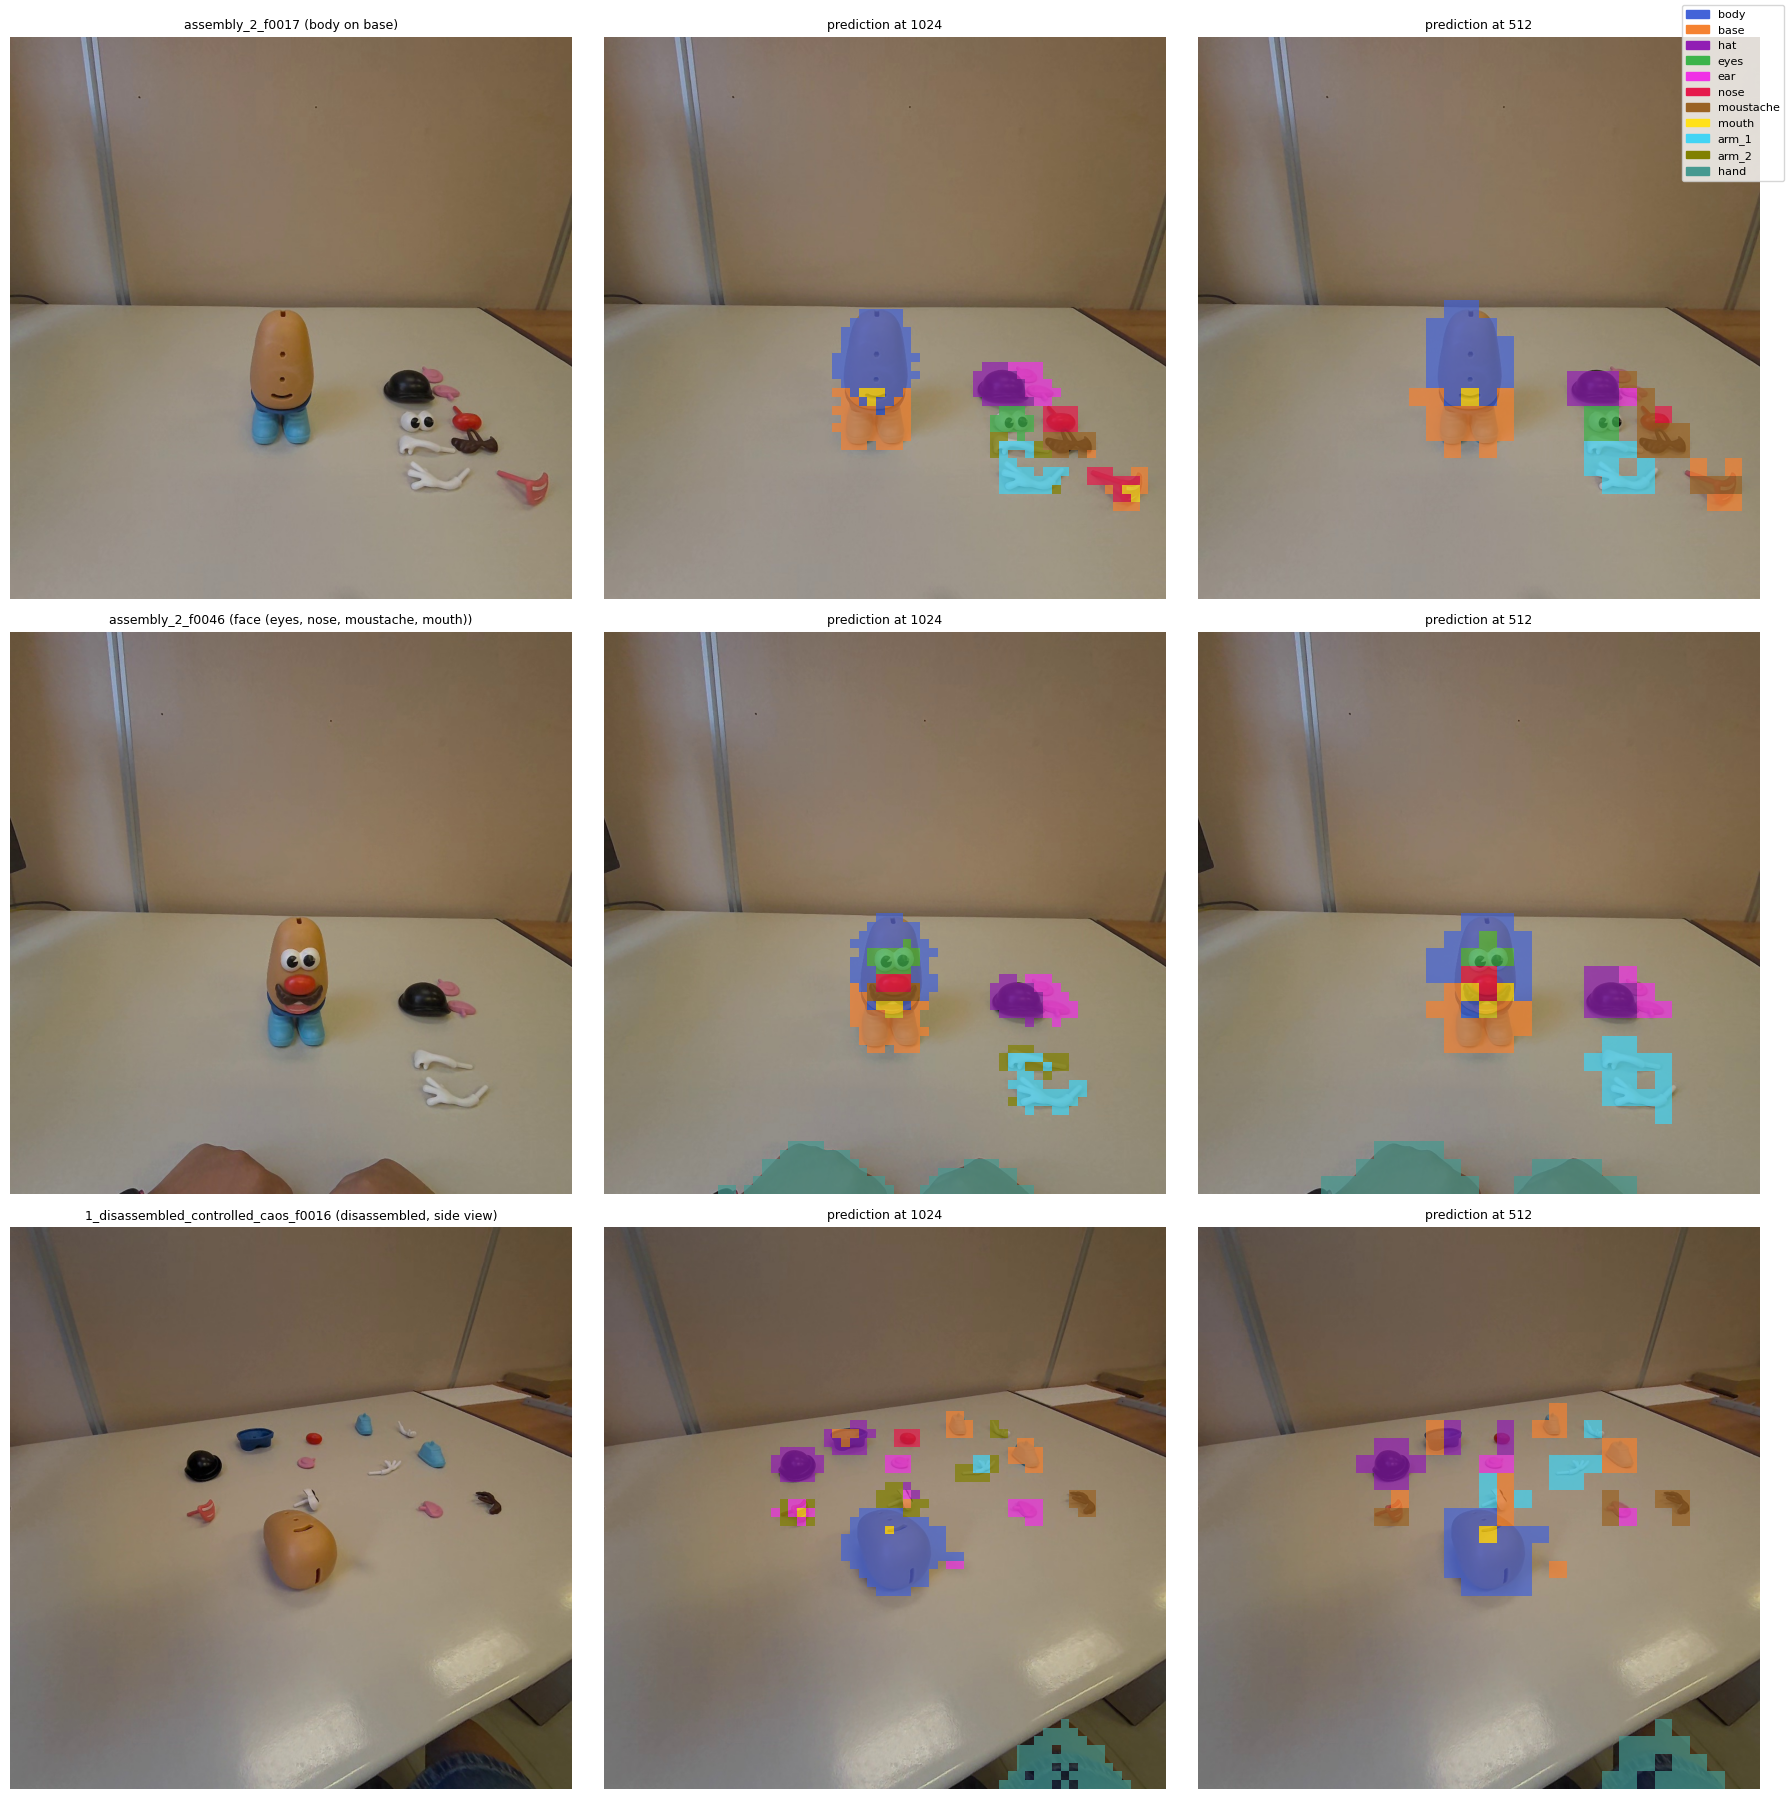

In [18]:
# 5.3 Predictions at 1024 and 512 on three frames chosen before running (background margin 0.03).
# assembly_2_f0017: empty mouth slot; assembly_2_f0046: small face pieces mounted;
# 1_disassembled_controlled_caos_f0016: loose mouth seen from the side.
FIGURE_FRAMES = ["assembly_2_f0017", "assembly_2_f0046", "1_disassembled_controlled_caos_f0016"]

fig, axes = plt.subplots(len(FIGURE_FRAMES), 3, figsize=(18, 6 * len(FIGURE_FRAMES)))
for row, name in zip(axes, FIGURE_FRAMES):
    val = next(v for v in VALIDATION_FRAMES if v["frame"] == name)
    image = Image.open(frame_path(name)).convert("RGB")
    row[0].imshow(image)
    row[0].set_title(f"{name} ({val['stage']})", fontsize=9)
    for ax, res in zip(row[1:], RESOLUTIONS):
        pred = predict(val["features"][res], PROTOTYPE_MATRIX[res], CONFIDENCE_MARGIN, res)
        alpha = np.where(pred == BACKGROUND_ID, 0.0, 0.7)[..., None]
        ax.imshow(image)
        ax.imshow(np.concatenate([label_grid_to_rgb(pred), alpha], axis=-1),
                  extent=(0, image.width, image.height, 0), interpolation="nearest")
        ax.set_title(f"prediction at {res}", fontsize=9)
    for ax in row:
        ax.axis("off")

legend = [mpatches.Patch(color=CLASS_COLORS[name], label=name) for name in CLASS_NAMES[1:]]
fig.legend(handles=legend, loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "predictions_1024_vs_512.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 5.3: At 512 the predicted regions are visibly coarser, in blocks of 32x32 pixels. Body, hat, eyes and the hands are found at both resolutions. The empty mouth slot in assembly_2_f0017 is predicted as mouth at both resolutions.

At 512 more loose pieces take the color of base. In assembly_2_f0017 the loose mouth, at the bottom right, is predicted as nose and mouth at 1024 and mostly as base at 512. In 1_disassembled_controlled_caos_f0016, several loose pieces are predicted as base at 512. In assembly_2_f0046 the mounted face at 512 is a mix of nose, mouth and body blocks, and the moustache does not appear. The olive patches of arm_2 visible at 1024 near the arms disappear at 512, where both arms are predicted as arm_1.

Hypothesis: base may act at 512 even more than at 1024 as the default class for appearances that the prototypes do not cover, as suggested in the pipeline for 1024 (pipeline, Section 10). This would explain part of the drop of base in 5.2, through false positives. It is not measured here.

In [19]:
# 5.4 Latency at 1024 and 512 (protocol of the pipeline, Section 12), resolutions alternated run by run
latency_image = Image.open(frame_path(VALIDATION_FRAMES[0]["frame"])).convert("RGB")


def timed(fn):
    """Run fn and return (result, elapsed milliseconds), waiting for the GPU before and after."""
    torch.cuda.synchronize()
    start = time.perf_counter()
    result = fn()
    torch.cuda.synchronize()
    return result, (time.perf_counter() - start) * 1000


def model_forward(pixel_values):
    with torch.no_grad(), torch.autocast(DEVICE, dtype=DTYPE):
        return extractor.model(pixel_values)


pixel_values = {res: extractor.preprocess(latency_image, res)[0] for res in RESOLUTIONS}
latency_features = {}
for res in RESOLUTIONS:                                   # warm-up, not measured
    for _ in range(N_WARMUP):
        latency_features[res], _ = extractor.extract(latency_image, resolution=res)
        classify_patches(latency_features[res], PROTOTYPE_MATRIX[res], CONFIDENCE_MARGIN)

STEPS = ["C-RADIO forward only", "feature extraction (resize + forward)", "classification"]
timings = {(res, step): [] for res in RESOLUTIONS for step in STEPS}
for _ in range(N_RUNS):
    for res in RESOLUTIONS:                               # alternated: slow drifts affect both resolutions alike
        timings[(res, STEPS[0])].append(timed(lambda: model_forward(pixel_values[res]))[1])
        timings[(res, STEPS[1])].append(timed(lambda: extractor.extract(latency_image, resolution=res))[1])
        timings[(res, STEPS[2])].append(
            timed(lambda: classify_patches(latency_features[res], PROTOTYPE_MATRIX[res], CONFIDENCE_MARGIN))[1])

perception = {res: np.array(timings[(res, STEPS[1])]) + np.array(timings[(res, STEPS[2])]) for res in RESOLUTIONS}
table = pd.DataFrame({f"median {res} (ms)": {**{s: np.median(timings[(res, s)]) for s in STEPS},
                                              "perception (extraction + classification)": np.median(perception[res])}
                      for res in RESOLUTIONS})
table["ratio 1024 / 512"] = table[f"median {NATIVE_RESOLUTION} (ms)"] / table[f"median {LOW_RESOLUTION} (ms)"]
display(table.round(1))
print(f"512 faster in every run: {perception[LOW_RESOLUTION].max() < perception[NATIVE_RESOLUTION].min()}")
print(f"GPU: {torch.cuda.get_device_name(0)}")

,median 1024 (ms),median 512 (ms),ratio 1024 / 512
C-RADIO forward only,358.1,66.9,5.3
feature extraction (resize + forward),381.5,87.6,4.4
classification,26.1,6.1,4.3
perception (extraction + classification),408.1,94.1,4.3


512 faster in every run: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


Observation 5.4: Perception takes about 410 ms per frame at 1024 and about 100 ms at 512, four times less, and 512 is faster in every one of the 50 runs. The C-RADIO forward pass goes from about 360 ms to about 70 ms, a ratio of about 5. Image preparation takes about 25 ms at both resolutions, since the frame is resized from 1024 in both cases, and classification goes from about 30 ms to about 8 ms.

At 512 perception would run at about 10 frames per second on this laptop, against about 2.5 at 1024. Both are far from the 30 frames per second of the video. Timings change between executions on this laptop (pipeline, Section 12), so they are rounded here; the ratio between the two resolutions is the more stable figure.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5:

Koehn 2004, Sect. 6: paired bootstrap resampling, two systems compared on the same resampled test sets 5.2.

Pipeline, Section 8: prototype similarity and the risky pairs 5.1; Section 12: latency protocol (warm-up, repeated runs, GPU synchronization) 5.4.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Conclusions

Result. The input resolution stays at 1024x1024, the native size of the headset frames. The choice was made in Section 1, before running 512, and Section 5 confirms it.

Why. At 512 the prototypes of the small pieces rest on very few patches: one for arm_2, two for mouth (4.1). Even perfect recognition on the 512 grid would not exceed what the method already reaches at 1024 (4.4). Run once, 512 loses about a quarter of the mIoU in every setting, mostly through recognition rather than through the coarser grid (5.2). The pieces that lose most, mouth and moustache, are among those Phase 2 depends on.

What 512 would gain. Perception would be about four times faster on this laptop, about 100 ms per frame instead of about 410 (5.4). This gain is not needed now: continuous perception runs offline, and the final system is planned as client-server, with C-RADIO on a server.

What changed in the protocol. The study was planned as a noninferiority decision (Piaggio et al. 2012). The oracles of Section 4 showed that, with patch-level IoU on the 1024 grid, 512 could pass only with almost perfect recognition, so the rule would have measured the grid rather than recognition. It was dropped before any feature was extracted at 512, and this is recorded in the history of the repository.

Limitations. Validation has 8 frames from two recordings, 6 from the same one, so the intervals are likely too narrow. The support set, the labelling rule and the background margin were all chosen at 1024, which favours 1024. The image at 512 is obtained by resizing the 1024 frame with a Lanczos filter: a camera streaming at 512 would give different images. Only one GPU, a laptop, was used for timing. The ear instances of the noninferiority margins are not separated in four frames (Observation 4.2); the margins were not used in the end.

Not studied. Other ways to reduce the time at 1024 were not tested: a stronger GPU, a crop of the working area at full resolution, or the windowed attention mode of the model (ViTDet), which the tech report describes (Sect. 3.2) but the configuration files of this model mark as not supported. The intermediate resolution 768 was left out (Section 1).

Next step. Continuous perception on assembly_2 at 1024, in a separate notebook. At about 410 ms per frame, the 2444 frames of the video take about 17 minutes offline on this laptop.